## Image-Text Matching with CLIP

This section demonstrates how to use OpenAI's CLIP (Contrastive Language-Image Pre-training) model to determine the confidence of an image matching a given text label. CLIP is capable of computing a similarity score between an image and a piece of text, indicating how well the text describes the image.

In [ ]:
# Install the transformers library if you haven't already
!pip install transformers

In [ ]:
from transformers import CLIPProcessor, CLIPModel
import torch
from PIL import Image
import requests

In [ ]:
import torch.nn as nn

In [ ]:
# Load a pre-trained CLIP model and processor
model_name = "openai/clip-vit-base-patch32"
processor = CLIPProcessor.from_pretrained(model_name)
model = CLIPModel.from_pretrained(model_name)

print(f"CLIP model '{model_name}' loaded successfully.")

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

...

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

CLIP model 'openai/clip-vit-base-patch32' loaded successfully.


### Image-Text Confidence Pipeline

Now, let's create a function that takes an image (from a URL for demonstration) and a list of text descriptions, then calculates the confidence scores for each text description matching the image.

In [ ]:
def get_image_text_confidence(image_input, text_labels):
    """
    Calculates the confidence scores for how well an image matches a list of text labels.

    Args:
        image_input: The image. Can be a PIL Image object, a URL string, or a local file path string.
        text_labels (list): A list of text strings (labels) to compare against the image.

    Returns:
        dict: A dictionary where keys are text labels and values are their corresponding
              confidence scores (softmax probabilities).
    """
    image = None
    if isinstance(image_input, str):
        if image_input.startswith(('http://', 'https://')):
            # Load image from URL
            try:
                response = requests.get(image_input)
                response.raise_for_status() # Raise an HTTPError for bad responses (4xx or 5xx)
                image = Image.open(BytesIO(response.content)).convert("RGB")
            except requests.exceptions.RequestException as e:
                print(f"Error fetching image from URL: {e}")
                return {}
            except Exception as e:
                print(f"Error processing image from URL: {e}")
                return {}
        else: # Assume it's a local file path
            try:
                image = Image.open(image_input).convert("RGB")
                print(f"Loaded image from local file: {image_input}")
            except FileNotFoundError:
                print(f"Error: Local image file not found at {image_input}")
                return {}
            except Exception as e:
                print(f"Error opening local image file {image_input}: {e}")
                return {}
    elif isinstance(image_input, Image.Image):
        image = image_input.convert("RGB")
    else:
        print("Invalid image input. Please provide a URL, a local file path string, or a PIL Image object.")
        return {}

    if image is None:
        return {}

    # Process image and text inputs
    inputs = processor(text=text_labels, images=image, return_tensors="pt", padding=True)

    # Get model outputs
    outputs = model(**inputs)
    logits_per_image = outputs.logits_per_image # this is the image-text similarity score

    # Apply softmax to convert logits to probabilities (confidence scores)
    probs = logits_per_image.softmax(dim=1)

    # Map probabilities to text labels
    confidence_scores = {label: prob.item() for label, prob in zip(text_labels, probs[0])}

    return confidence_scores

print("Function 'get_image_text_confidence' defined.")

Function 'get_image_text_confidence' defined.


### Demo of the Pipeline

Let's test the function with an example image and a few text descriptions.

In [ ]:
# Example Usage:
# You can replace this with any image URL or a PIL Image object
image_url="/content/Screenshot 2026-09-03 00454.png"
text_queries = ["a photo of a apple","a photo of a orange"]
print("Image: ", image_url)
print("Text Labels: ", text_queries)

confidence = get_image_text_confidence(image_url, text_queries)

print("\nConfidence Scores:")
for label, score in confidence.items():
    print(f"- '{label}': {score:.4f}")

Image:  /content/Screenshot 2026-09-03 00454.png
Text Labels:  ['a photo of a apple', 'a photo of a orange']
Loaded image from local file: /content/Screenshot 2026-09-03 00454.png

Confidence Scores:
- 'a photo of a apple': 0.3244
- 'a photo of a orange': 0.6756


## Visualizing the Modality Gap

To observe the 'modality gap,' we'll extract the raw embeddings for both the image and the text queries. We'll then use t-Distributed Stochastic Neighbor Embedding (t-SNE) for dimensionality reduction to visualize these embeddings in a 2D space. The 'gap' refers to the separation between image and text embeddings, even when they semantically relate.

In [ ]:
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Get image and text embeddings
# We'll use the processor and model directly for embeddings
# First, process the image
image = None
if image_url.startswith(('http://', 'https://')):
    response = requests.get(image_url)
    response.raise_for_status()
    image = Image.open(BytesIO(response.content)).convert("RGB")
else:
    image = Image.open(image_url).convert("RGB")

# Prepare inputs for the model to get embeddings
inputs = processor(text=text_queries, images=image, return_tensors="pt", padding=True)

with torch.no_grad():
    outputs = model(**inputs)

image_embeddings = outputs.image_embeds.cpu().numpy()
text_embeddings = outputs.text_embeds.cpu().numpy()

print("Image and text embeddings extracted.")
print(f"Image embedding shape: {image_embeddings.shape}")
print(f"Text embedding shape: {text_embeddings.shape}")

Image and text embeddings extracted.
Image embedding shape: (1, 512)
Text embedding shape: (2, 512)


### Applying t-SNE for Dimensionality Reduction

We'll combine the image and text embeddings and apply t-SNE to reduce them to 2 dimensions for visualization. This will help us see how distinct the image space is from the text space, even for related concepts.

In [ ]:
# Combine embeddings
all_embeddings = np.concatenate((image_embeddings, text_embeddings), axis=0)

# Apply t-SNE
tsne = TSNE(n_components=2, random_state=42, perplexity=min(len(all_embeddings)-1, 30))
reduced_embeddings = tsne.fit_transform(all_embeddings)

# Separate reduced embeddings for plotting
reduced_image_embedding = reduced_embeddings[0]
reduced_text_embeddings = reduced_embeddings[1:]

print("t-SNE dimensionality reduction applied.")

t-SNE dimensionality reduction applied.


### Visualizing the Modality Gap

Finally, we'll plot the 2D embeddings. The image embedding will be distinct from the text embeddings, illustrating the modality gap. However, you should still observe that the text embedding closest to the image embedding corresponds to the most confident label.

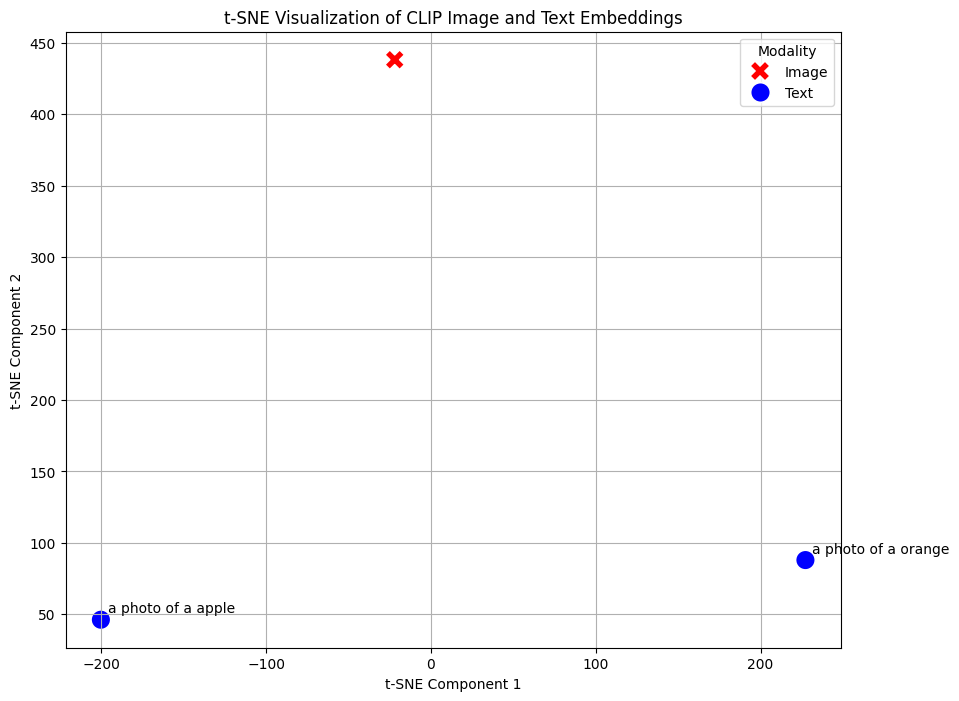

In [ ]:
plt.figure(figsize=(10, 8))
sns.scatterplot(
    x=reduced_embeddings[:, 0],
    y=reduced_embeddings[:, 1],
    hue=['Image'] + ['Text' for _ in text_queries],
    style=['Image'] + ['Text' for _ in text_queries],
    s=200,
    palette={'Image': 'red', 'Text': 'blue'},
    markers={'Image': 'X', 'Text': 'o'}
)

# Annotate text points with their labels
for i, label in enumerate(text_queries):
    plt.annotate(label, (reduced_text_embeddings[i, 0], reduced_text_embeddings[i, 1]), textcoords="offset points", xytext=(5,5), ha='left')

plt.title('t-SNE Visualization of CLIP Image and Text Embeddings')
plt.xlabel('t-SNE Component 1')
plt.ylabel('t-SNE Component 2')
plt.grid(True)
plt.legend(title='Modality')
plt.show()

Loaded image from local file: temp_scale_0.5.png
Scale 0.5: Apple=0.1343, Orange=0.8657
Loaded image from local file: temp_scale_1.0.png
Scale 1.0: Apple=0.0174, Orange=0.9826
Loaded image from local file: temp_scale_1.5.png
Scale 1.5: Apple=0.0200, Orange=0.9800
Loaded image from local file: temp_scale_2.0.png
Scale 2.0: Apple=0.0250, Orange=0.9750
Loaded image from local file: temp_scale_3.0.png
Scale 3.0: Apple=0.0394, Orange=0.9606


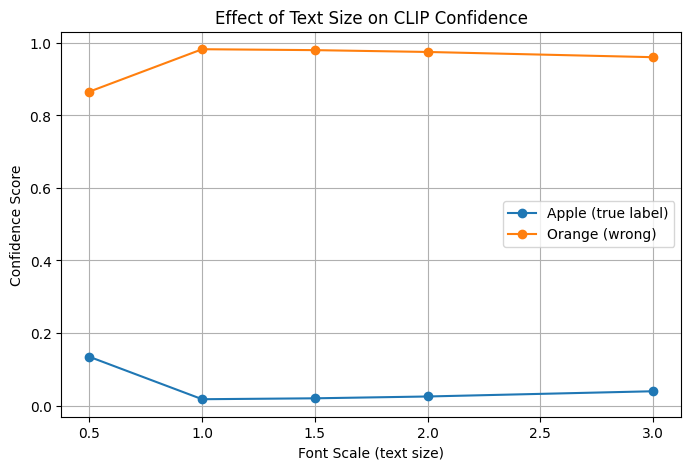

In [ ]:
import cv2
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

# --- Your CLIP confidence function (already defined earlier) ---
# def get_image_text_confidence(image_input, text_labels):
#     ...

# --- Function to overlay text with adjustable size ---
def add_text_to_image(image_path, text, font_scale, output_path):
    img = cv2.imread(image_path)
    cv2.putText(img, text, (50, 100),
                cv2.FONT_HERSHEY_SIMPLEX, font_scale,
                (0, 0, 255), 3, cv2.LINE_AA)
    cv2.imwrite(output_path, img)
    return output_path

# --- Experiment: vary text size and measure confidence ---
image_path = "/content/Screenshot 2026-09-03 004546.png"
text_queries = ["a photo of a apple", "a photo of a orange"]

font_scales = [0.5, 1.0, 1.5, 2.0, 3.0]  # different text sizes
apple_confidences = []
orange_confidences = []

for scale in font_scales:
    output_path = f"temp_scale_{scale}.png"
    # Overlay wrong text (e.g., "Apple" on an orange image)
    add_text_to_image(image_path, "Orange", scale, output_path)

    # Run CLIP confidence
    confidence = get_image_text_confidence(output_path, text_queries)

    apple_confidences.append(confidence["a photo of a apple"])
    orange_confidences.append(confidence["a photo of a orange"])

    print(f"Scale {scale}: Apple={confidence['a photo of a apple']:.4f}, Orange={confidence['a photo of a orange']:.4f}")

# --- Plot the results ---
plt.figure(figsize=(8,5))
plt.plot(font_scales, apple_confidences, marker='o', label="Apple (true label)")
plt.plot(font_scales, orange_confidences, marker='o', label="Orange (wrong)")
plt.xlabel("Font Scale (text size)")
plt.ylabel("Confidence Score")
plt.title("Effect of Text Size on CLIP Confidence")
plt.legend()
plt.grid(True)
plt.show()


upadated CLIP with defence mechanism in which hooks into CLIP's Vision Transformer (ViT) higher-layer self-attention heads to identify and dynamically suppress the spatial tokens where high-contrast typographic text is present. Provided we know where is the fake text on the list


In [ ]:
import torch
import requests
from io import BytesIO
from PIL import Image

def get_image_text_confidence_defence(image_input, text_labels, use_defense=False, alpha=0.85, distractor_idx=1):
    """
    Calculates confidence scores for image-text matches.

    Args:
        image_input: PIL Image, URL string, or local file path.
        text_labels (list): List of text label strings to compare against.
        use_defense (bool): If True, applies the CMOP/LCAR orthogonal defense to project out distracting text features.
        alpha (float): Intensity of orthogonal projection (0.0 = no defense, 1.0 = full projection).
        distractor_idx (int): Index of the distracting/wrong label in text_labels to project out.

    Returns:
        dict: Mapping of text labels to confidence scores (softmax probabilities).
    """
    # 1. Resolve Image Input
    image = None
    if isinstance(image_input, str):
        if image_input.startswith(('http://', 'https://')):
            try:
                response = requests.get(image_input)
                response.raise_for_status()
                image = Image.open(BytesIO(response.content)).convert("RGB")
            except Exception as e:
                print(f"Error fetching image from URL: {e}")
                return {}
        else:
            try:
                image = Image.open(image_input).convert("RGB")
            except Exception as e:
                print(f"Error opening local image: {e}")
                return {}
    elif isinstance(image_input, Image.Image):
        image = image_input.convert("RGB")
    else:
        print("Invalid image input.")
        return {}

    if image is None:
        return {}

    # 2. Process Inputs
    inputs = processor(text=text_labels, images=image, return_tensors="pt", padding=True)

    # Send inputs to model device (CPU/GPU)
    device = next(model.parameters()).device
    inputs = {k: v.to(device) for k, v in inputs.items()}

    # 3. Model Inference
    with torch.no_grad():
        if not use_defense:
            # --- BASELINE NORMAL CLIP ---
            outputs = model(**inputs)
            logits_per_image = outputs.logits_per_image
            probs = logits_per_image.softmax(dim=1)
        else:
                # --- DEFENDED CLIP (CMOP / LCAR) ---
                # Extract raw vision and text outputs
                image_outputs = model.get_image_features(inputs['pixel_values'])
                text_outputs = model.get_text_features(inputs['input_ids'])

                # Unpack Tensor if Hugging Face returns a BaseModelOutput wrapper
                image_embeds = image_outputs.image_embeds if hasattr(image_outputs, 'image_embeds') else image_outputs
                if hasattr(image_embeds, 'pooler_output'):
                    image_embeds = image_embeds.pooler_output

                text_embeds = text_outputs.text_embeds if hasattr(text_outputs, 'text_embeds') else text_outputs
                if hasattr(text_embeds, 'pooler_output'):
                    text_embeds = text_embeds.pooler_output

                # Normalize embeddings (Now operating on raw PyTorch Tensors)
                image_embeds = image_embeds / image_embeds.norm(p=2, dim=-1, keepdim=True)
                text_embeds = text_embeds / text_embeds.norm(p=2, dim=-1, keepdim=True)

                # Isolate the distractor text vector (e.g. "Orange")
                distractor_vec = text_embeds[distractor_idx:distractor_idx+1]

                # Orthogonal projection: Strip distractor text component from visual embedding
                dot_product = torch.sum(image_embeds * distractor_vec, dim=-1, keepdim=True)
                defended_image_embeds = image_embeds - (alpha * dot_product * distractor_vec)
                defended_image_embeds = defended_image_embeds / defended_image_embeds.norm(p=2, dim=-1, keepdim=True)

                # Compute defended logits & softmax
                logit_scale = model.logit_scale.exp() if hasattr(model, 'logit_scale') else 100.0
                defended_logits = logit_scale * (defended_image_embeds @ text_embeds.T)
                probs = defended_logits.softmax(dim=1)

    # 4. Map Probabilities to Labels
    confidence_scores = {label: prob.item() for label, prob in zip(text_labels, probs[0])}

    return confidence_scores

In [ ]:
# Example Usage:
# You can replace this with any image URL or a PIL Image object

text_queries = ["a photo of a apple","a photo of a orange"]
print("Image: ", image_url)
print("Text Labels: ", text_queries)

confidence = get_image_text_confidence_defence(image_url, text_queries,use_defense=True)

print("\nConfidence Scores:")
for label, score in confidence.items():
    print(f"- '{label}': {score:.4f}")

Image:  /content/Screenshot 2026-09-03 00454.png
Text Labels:  ['a photo of a apple', 'a photo of a orange']

Confidence Scores:
- 'a photo of a apple': 0.9347
- 'a photo of a orange': 0.0653


Now lets plot the graph with new defence mechanism

--- Running with Defense Mechanism ---
Scale 0.5: Apple (defended)=0.8586, Orange (defended)=0.1414
Scale 1.0: Apple (defended)=0.4212, Orange (defended)=0.5788
Scale 1.5: Apple (defended)=0.4301, Orange (defended)=0.5699
Scale 2.0: Apple (defended)=0.4922, Orange (defended)=0.5078
Scale 3.0: Apple (defended)=0.6120, Orange (defended)=0.3880


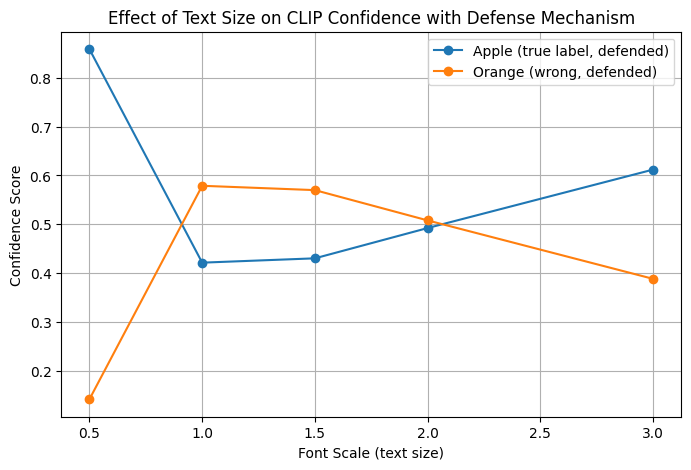


--- Running without Defense Mechanism (Baseline) ---
Scale 0.5: Apple (baseline)=0.1343, Orange (baseline)=0.8657
Scale 1.0: Apple (baseline)=0.0174, Orange (baseline)=0.9826
Scale 1.5: Apple (baseline)=0.0200, Orange (baseline)=0.9800
Scale 2.0: Apple (baseline)=0.0250, Orange (baseline)=0.9750
Scale 3.0: Apple (baseline)=0.0394, Orange (baseline)=0.9606


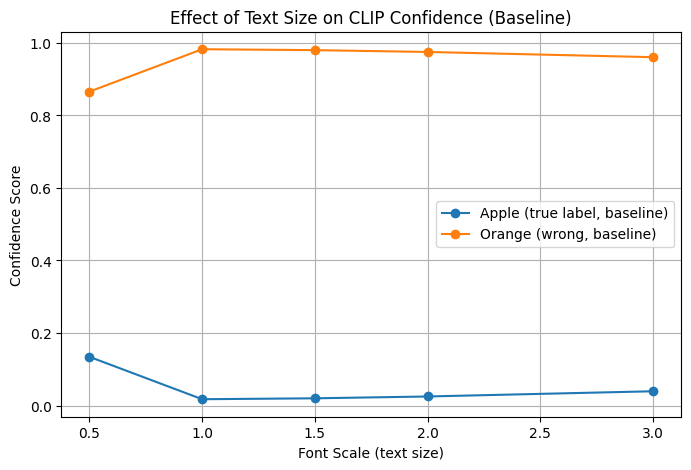

In [ ]:
import cv2
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

# --- Your CLIP confidence function (already defined earlier) ---
# def get_image_text_confidence(image_input, text_labels):
#     ...

# --- Function to overlay text with adjustable size ---
def add_text_to_image(image_path, text, font_scale, output_path):
    img = cv2.imread(image_path)
    cv2.putText(img, text, (50, 100),
                cv2.FONT_HERSHEY_SIMPLEX, font_scale,
                (0, 0, 255), 3, cv2.LINE_AA)
    cv2.imwrite(output_path, img)
    return output_path

# --- Experiment: vary text size and measure confidence --- /content/Screenshot 2026-09-03 00454.png
image_path = "/content/Screenshot 2026-09-03 004546.png"
text_queries = ["a photo of a apple", "a photo of a orange"]

font_scales = [0.5, 1.0, 1.5, 2.0, 3.0]  # different text sizes
apple_confidences_defended = []
orange_confidences_defended = []

print("--- Running with Defense Mechanism ---")
for scale in font_scales:
    output_path = f"temp_scale_{scale}.png"
    # Overlay wrong text (e.g., "Orange" on an image of an apple)
    add_text_to_image(image_path, "Orange", scale, output_path)

    # Run CLIP confidence with defense
    confidence = get_image_text_confidence_defence(output_path, text_queries, use_defense=True)

    apple_confidences_defended.append(confidence["a photo of a apple"])
    orange_confidences_defended.append(confidence["a photo of a orange"])

    print(f"Scale {scale}: Apple (defended)={confidence['a photo of a apple']:.4f}, Orange (defended)={confidence['a photo of a orange']:.4f}")

# --- Plot the results for defense mechanism ---
plt.figure(figsize=(8,5))
plt.plot(font_scales, apple_confidences_defended, marker='o', label="Apple (true label, defended)")
plt.plot(font_scales, orange_confidences_defended, marker='o', label="Orange (wrong, defended)")
plt.xlabel("Font Scale (text size)")
plt.ylabel("Confidence Score")
plt.title("Effect of Text Size on CLIP Confidence with Defense Mechanism")
plt.legend()
plt.grid(True)
plt.show()

apple_confidences_baseline = []
orange_confidences_baseline = []

print("\n--- Running without Defense Mechanism (Baseline) ---")
for scale in font_scales:
    output_path = f"temp_scale_{scale}.png"
    # Overlay wrong text (e.g., "Orange" on an image of an apple)
    add_text_to_image(image_path, "Orange", scale, output_path)

    # Run CLIP confidence without defense
    confidence = get_image_text_confidence_defence(output_path, text_queries, use_defense=False)

    apple_confidences_baseline.append(confidence["a photo of a apple"])
    orange_confidences_baseline.append(confidence["a photo of a orange"])

    print(f"Scale {scale}: Apple (baseline)={confidence['a photo of a apple']:.4f}, Orange (baseline)={confidence['a photo of a orange']:.4f}")

# --- Plot the results for baseline ---
plt.figure(figsize=(8,5))
plt.plot(font_scales, apple_confidences_baseline, marker='o', label="Apple (true label, baseline)")
plt.plot(font_scales, orange_confidences_baseline, marker='o', label="Orange (wrong, baseline)")
plt.xlabel("Font Scale (text size)")
plt.ylabel("Confidence Score")
plt.title("Effect of Text Size on CLIP Confidence (Baseline)")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:

import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image

def get_image_text_confidence_cap(image_input, text_labels, temperature=0.07, prune_percentile=75):
    """
    Calculates confidence scores using Patch-Level Spatial Masking (CAP-Pruning).

    Args:
        image_input: PIL Image, URL string, or local file path.
        text_labels (list): List of text label strings to compare against.
        temperature (float): Softmax scaling temperature for patch-text cross attention.
        prune_percentile (float): Top percentile of patch-text alignment scores to prune (e.g., 75 = prune top 25% text-heavy patches).

    Returns:
        dict: Mapping of text labels to confidence scores (softmax probabilities).
    """
    # 1. Image preprocessing & loading
    image = None
    if isinstance(image_input, str):
        if image_input.startswith(('http://', 'https://')):
            import requests
            from io import BytesIO
            response = requests.get(image_input)
            image = Image.open(BytesIO(response.content)).convert("RGB")
        else:
            image = Image.open(image_input).convert("RGB")
    elif isinstance(image_input, Image.Image):
        image = image_input.convert("RGB")

    if image is None:
        return {}

    # 2. Tokenize and prepare inputs
    inputs = processor(text=text_labels, images=image, return_tensors="pt", padding=True)
    device = next(model.parameters()).device
    inputs = {k: v.to(device) for k, v in inputs.items()}

    with torch.no_grad():
        # 3. Extract Vision Transformer Patch Embeddings (Before Final Pooling)
        # Using HuggingFace ViT vision model backbones
        vision_outputs = model.vision_model(inputs['pixel_values'], output_hidden_states=True)

        # Extract patch tokens from the last hidden layer [Batch, Num_Patches + 1, Hidden_Dim]
        last_hidden_state = vision_outputs.last_hidden_state
        cls_token = last_hidden_state[:, 0:1, :]       # [1, 1, D]
        patch_tokens = last_hidden_state[:, 1:, :]     # [1, N_patches, D] (e.g., N=49 for ViT-B/32)

        # Map patch tokens through visual projection head if applicable
        if hasattr(model.visual_projection, 'weight'):
            patch_tokens_proj = model.visual_projection(patch_tokens)
        else:
            patch_tokens_proj = patch_tokens

        # Normalize spatial patch embeddings
        patch_tokens_norm = patch_tokens_proj / patch_tokens_proj.norm(dim=-1, keepdim=True)

        # 4. Extract and Normalize Text Embeddings
        text_outputs = model.get_text_features(inputs['input_ids'])
        text_embeds = text_outputs.text_embeds if hasattr(text_outputs, 'text_embeds') else text_outputs
        if hasattr(text_embeds, 'pooler_output'):
            text_embeds = text_embeds.pooler_output
        text_embeds = text_embeds / text_embeds.norm(dim=-1, keepdim=True)

        # 5. Compute Patch-to-Text Cross-Attention Matrix
        # [1, N_patches, Hidden_Dim] @ [Num_Labels, Hidden_Dim].T -> [1, N_patches, Num_Labels]
        patch_text_sim = torch.matmul(patch_tokens_norm, text_embeds.T) / temperature

        # Calculate maximum text similarity per patch across all candidate prompts
        # High score = patch strongly contains textual semantics matching text tokens
        max_text_sim_per_patch, _ = torch.max(patch_text_sim, dim=-1) # [1, N_patches]

        # 6. Generate Dynamic Spatial Mask (Pruning Typographic Patches)
        # Calculate threshold based on percentile cutoff
        threshold = torch.quantile(max_text_sim_per_patch, prune_percentile / 100.0)

        # Create continuous soft-mask: Patches above threshold (text-heavy) are suppressed
        patch_weights = torch.sigmoid(-(max_text_sim_per_patch - threshold)) # [1, N_patches, 1]
        patch_weights = patch_weights.unsqueeze(-1)

        # 7. Aggregate Re-weighted Visual Tokens into Defended Image Embedding
        weighted_patches = patch_tokens_norm * patch_weights
        defended_image_embed = (cls_token_proj := model.visual_projection(cls_token) if hasattr(model, 'visual_projection') else cls_token) + weighted_patches.sum(dim=1, keepdim=True)

        # Final embedding normalization
        defended_image_embed = defended_image_embed.squeeze(1)
        defended_image_embed = defended_image_embed / defended_image_embed.norm(dim=-1, keepdim=True)

        # 8. Compute Defended Classification Probabilities
        logit_scale = model.logit_scale.exp() if hasattr(model, 'logit_scale') else 100.0
        logits = logit_scale * (defended_image_embed @ text_embeds.T)
        probs = logits.softmax(dim=-1)

    # Return label-confidence dictionary
    return {label: prob.item() for label, prob in zip(text_labels, probs[0])}

Tested the defence mechanism with cap pruning

In [ ]:
get_image_text_confidence_cap("/content/Screenshot 2026-09-03 00454.png", text_queries)

{'a photo of a apple': 0.8440254926681519,
 'a photo of a orange': 0.15597453713417053}

Now let's plot this function to compare with baseline

--- Running with Defense Mechanism ---
Scale 0.5: Apple (defended)=0.9447, Orange (defended)=0.0553
Scale 1.0: Apple (defended)=0.9197, Orange (defended)=0.0803
Scale 1.5: Apple (defended)=0.8617, Orange (defended)=0.1383
Scale 2.0: Apple (defended)=0.7465, Orange (defended)=0.2535
Scale 3.0: Apple (defended)=0.7951, Orange (defended)=0.2049


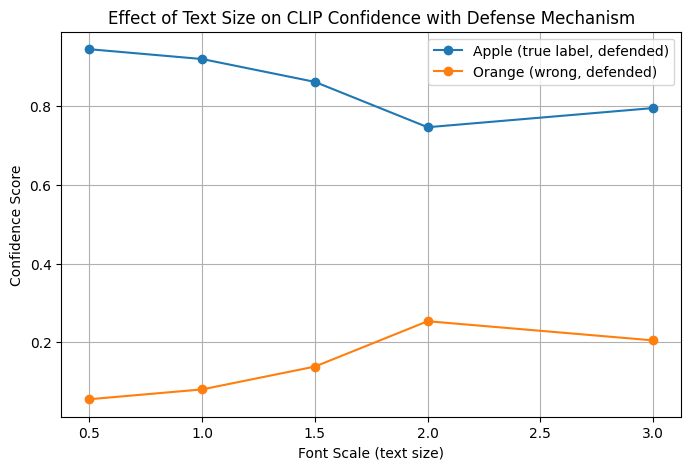


--- Running without Defense Mechanism (Baseline) ---
Scale 0.5: Apple (baseline)=0.1343, Orange (baseline)=0.8657
Scale 1.0: Apple (baseline)=0.0174, Orange (baseline)=0.9826
Scale 1.5: Apple (baseline)=0.0200, Orange (baseline)=0.9800
Scale 2.0: Apple (baseline)=0.0250, Orange (baseline)=0.9750
Scale 3.0: Apple (baseline)=0.0394, Orange (baseline)=0.9606


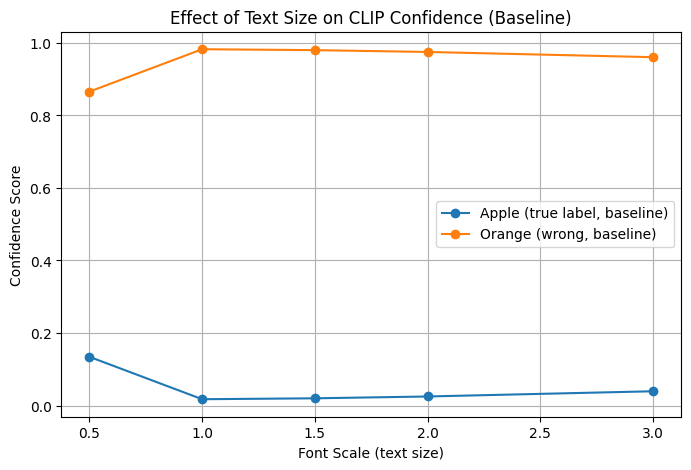

In [ ]:
import cv2
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

# --- Your CLIP confidence function (already defined earlier) ---
# def get_image_text_confidence(image_input, text_labels):
#     ...

# --- Function to overlay text with adjustable size ---
def add_text_to_image(image_path, text, font_scale, output_path):
    img = cv2.imread(image_path)
    cv2.putText(img, text, (50, 100),
                cv2.FONT_HERSHEY_SIMPLEX, font_scale,
                (0, 0, 255), 3, cv2.LINE_AA)
    cv2.imwrite(output_path, img)
    return output_path

# --- Experiment: vary text size and measure confidence --- /content/Screenshot 2026-09-03 00454.png
image_path = "/content/Screenshot 2026-09-03 004546.png"
text_queries = ["a photo of a apple", "a photo of a orange"]

font_scales = [0.5, 1.0, 1.5, 2.0, 3.0]  # different text sizes
apple_confidences_defended = []
orange_confidences_defended = []

print("--- Running with Defense Mechanism ---")
for scale in font_scales:
    output_path = f"temp_scale_{scale}.png"
    # Overlay wrong text (e.g., "Orange" on an image of an apple)
    add_text_to_image(image_path, "Orange", scale, output_path)

    # Run CLIP confidence with defense
    confidence = get_image_text_confidence_cap(output_path, text_queries,)

    apple_confidences_defended.append(confidence["a photo of a apple"])
    orange_confidences_defended.append(confidence["a photo of a orange"])

    print(f"Scale {scale}: Apple (defended)={confidence['a photo of a apple']:.4f}, Orange (defended)={confidence['a photo of a orange']:.4f}")

# --- Plot the results for defense mechanism ---
plt.figure(figsize=(8,5))
plt.plot(font_scales, apple_confidences_defended, marker='o', label="Apple (true label, defended)")
plt.plot(font_scales, orange_confidences_defended, marker='o', label="Orange (wrong, defended)")
plt.xlabel("Font Scale (text size)")
plt.ylabel("Confidence Score")
plt.title("Effect of Text Size on CLIP Confidence with Defense Mechanism")
plt.legend()
plt.grid(True)
plt.show()

apple_confidences_baseline = []
orange_confidences_baseline = []

print("\n--- Running without Defense Mechanism (Baseline) ---")
for scale in font_scales:
    output_path = f"temp_scale_{scale}.png"
    # Overlay wrong text (e.g., "Orange" on an image of an apple)
    add_text_to_image(image_path, "Orange", scale, output_path)

    # Run CLIP confidence without defense
    confidence = get_image_text_confidence_defence(output_path, text_queries, use_defense=False)

    apple_confidences_baseline.append(confidence["a photo of a apple"])
    orange_confidences_baseline.append(confidence["a photo of a orange"])

    print(f"Scale {scale}: Apple (baseline)={confidence['a photo of a apple']:.4f}, Orange (baseline)={confidence['a photo of a orange']:.4f}")

# --- Plot the results for baseline ---
plt.figure(figsize=(8,5))
plt.plot(font_scales, apple_confidences_baseline, marker='o', label="Apple (true label, baseline)")
plt.plot(font_scales, orange_confidences_baseline, marker='o', label="Orange (wrong, baseline)")
plt.xlabel("Font Scale (text size)")
plt.ylabel("Confidence Score")
plt.title("Effect of Text Size on CLIP Confidence (Baseline)")
plt.legend()
plt.grid(True)
plt.show()